<a href="https://colab.research.google.com/github/mukeshmanikandan/Data_Analysis_Advanced/blob/main/Lung_Disease_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [ ]:
dataset=pd.read_csv('survey lung cancer.csv')
dataset_emr=dataset.copy()

In [ ]:
dataset

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,F,56,1,1,1,2,2,2,1,1,2,2,2,2,1,YES
305,M,70,2,1,1,1,1,2,2,2,2,2,2,1,2,YES
306,M,58,2,1,1,1,1,1,2,2,2,2,1,1,2,YES
307,M,67,2,1,2,1,1,2,2,1,2,2,2,1,2,YES


In [ ]:

dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   GENDER                 309 non-null    object
 1   AGE                    309 non-null    int64 
 2   SMOKING                309 non-null    int64 
 3   YELLOW_FINGERS         309 non-null    int64 
 4   ANXIETY                309 non-null    int64 
 5   PEER_PRESSURE          309 non-null    int64 
 6   CHRONIC DISEASE        309 non-null    int64 
 7   FATIGUE                309 non-null    int64 
 8   ALLERGY                309 non-null    int64 
 9   WHEEZING               309 non-null    int64 
 10  ALCOHOL CONSUMING      309 non-null    int64 
 11  COUGHING               309 non-null    int64 
 12  SHORTNESS OF BREATH    309 non-null    int64 
 13  SWALLOWING DIFFICULTY  309 non-null    int64 
 14  CHEST PAIN             309 non-null    int64 
 15  LUNG_CANCER            

In [ ]:
dataset.value_counts()

GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  CHRONIC DISEASE  FATIGUE   ALLERGY   WHEEZING  ALCOHOL CONSUMING  COUGHING  SHORTNESS OF BREATH  SWALLOWING DIFFICULTY  CHEST PAIN  LUNG_CANCER
F       58   2        2               2        2              1                2         1         1         1                  2         2                    2                      1           YES            2
M       69   1        1               2        1              1                2         1         2         2                  2         2                    2                      1           YES            2
        67   2        1               2        1              1                2         2         1         2                  2         2                    1                      2           YES            2
             1        1               1        2              1                2         1         2         1                  2         2                    1                      2           YES            2
F       61   1        2               2        2              1                1         2         2         1                  2         1                    2                      1           YES            2
                                                                                                                                                                                                                ..
        69   1        1               1        1              2                2         1         1         1                  1         1                    1                      1           YES            1
        68   2        2               2        2              2                2         1         1         1                  2         2                    1                      1           YES            1
                      1               2        1              1                2         1         1         1                  1         1                    1                      1           NO             1
             1        1               2        1              2                1         2         2         2                  1         1                    2                      1           YES            1
        70   1        2               1        2              2                2         2         1         2                  2         1                    1                      1           YES            1
Name: count, Length: 276, dtype: int64

In [ ]:
for row in dataset.iterrows():
  print(row)

Streaming output truncated to the last 5000 lines.
LUNG_CANCER              NO
Name: 14, dtype: object)
(15, GENDER                     F
AGE                       48
SMOKING                    1
YELLOW_FINGERS             2
ANXIETY                    2
PEER_PRESSURE              2
CHRONIC DISEASE            2
FATIGUE                    2
ALLERGY                    2
WHEEZING                   2
ALCOHOL CONSUMING          1
COUGHING                   2
SHORTNESS OF BREATH        2
SWALLOWING DIFFICULTY      2
CHEST PAIN                 1
LUNG_CANCER              YES
Name: 15, dtype: object)
(16, GENDER                     M
AGE                       75
SMOKING                    2
YELLOW_FINGERS             1
ANXIETY                    1
PEER_PRESSURE              1
CHRONIC DISEASE            2
FATIGUE                    1
ALLERGY                    2
WHEEZING                   2
ALCOHOL CONSUMING          2
COUGHING                   2
SHORTNESS OF BREATH        2
SWALLOWING DIFFICULT

In [ ]:
dataset[['GENDER','LUNG_CANCER']].value_counts()

GENDER  LUNG_CANCER
M       YES            145
F       YES            125
        NO              22
M       NO              17
Name: count, dtype: int64

In [ ]:
dataset

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,F,56,1,1,1,2,2,2,1,1,2,2,2,2,1,YES
305,M,70,2,1,1,1,1,2,2,2,2,2,2,1,2,YES
306,M,58,2,1,1,1,1,1,2,2,2,2,1,1,2,YES
307,M,67,2,1,2,1,1,2,2,1,2,2,2,1,2,YES


In [ ]:
dataset.dtypes

,0
GENDER,object
AGE,int64
SMOKING,int64
YELLOW_FINGERS,int64
ANXIETY,int64
PEER_PRESSURE,int64
CHRONIC DISEASE,int64
FATIGUE,int64
ALLERGY,int64
WHEEZING,int64


In [ ]:
dataset['GENDER'].value_counts()

,count
GENDER,
M,162
F,147


In [ ]:
dataset['GENDER'].head()

,GENDER
0,M
1,M
2,F
3,M
4,F


In [ ]:
dataset['GENDER'] = (
    dataset['GENDER']
    .astype(str)          # handle NaN & mixed types
    .str.strip()          # remove spaces
    .str.upper()          # normalize case
    .eq('M')              # True if M else False
    .astype(int)          # True→1, False→0
)


In [ ]:
dataset

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,1,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,0,56,1,1,1,2,2,2,1,1,2,2,2,2,1,YES
305,1,70,2,1,1,1,1,2,2,2,2,2,2,1,2,YES
306,1,58,2,1,1,1,1,1,2,2,2,2,1,1,2,YES
307,1,67,2,1,2,1,1,2,2,1,2,2,2,1,2,YES


In [ ]:
dataset['GENDER'].value_counts()

,count
GENDER,
1,162
0,147


In [ ]:
dataset['LUNG_CANCER']=(dataset['LUNG_CANCER'].astype(str).str.strip().str.upper().eq('YES').astype(int))

In [ ]:
dataset

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2,1
1,1,74,2,1,1,1,2,2,2,1,1,1,2,2,2,1
2,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2,0
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2,0
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,0,56,1,1,1,2,2,2,1,1,2,2,2,2,1,1
305,1,70,2,1,1,1,1,2,2,2,2,2,2,1,2,1
306,1,58,2,1,1,1,1,1,2,2,2,2,1,1,2,1
307,1,67,2,1,2,1,1,2,2,1,2,2,2,1,2,1


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [ ]:
x=dataset.drop(columns=['LUNG_CANCER'])
y=dataset['LUNG_CANCER']

In [ ]:
x,y

(     GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
 0         1   69        1               2        2              1   
 1         1   74        2               1        1              1   
 2         0   59        1               1        1              2   
 3         1   63        2               2        2              1   
 4         0   63        1               2        1              1   
 ..      ...  ...      ...             ...      ...            ...   
 304       0   56        1               1        1              2   
 305       1   70        2               1        1              1   
 306       1   58        2               1        1              1   
 307       1   67        2               1        2              1   
 308       1   62        1               1        1              2   
 
      CHRONIC DISEASE  FATIGUE   ALLERGY   WHEEZING  ALCOHOL CONSUMING  \
 0                  1         2         1         2                  2   
 1        

In [ ]:
plot_self= dataset.head()

dataset.isnull().sum()

,0
GENDER,0
AGE,0
SMOKING,0
YELLOW_FINGERS,0
ANXIETY,0
PEER_PRESSURE,0
CHRONIC DISEASE,0
FATIGUE,0
ALLERGY,0
WHEEZING,0


In [ ]:
x.describe()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
count,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000
mean,0.524272,62.673139,1.563107,1.569579,1.498382,1.501618,1.504854,1.673139,1.556634,1.556634,1.556634,1.579288,1.640777,1.469256,1.556634
std,0.500221,8.210301,0.496806,0.495938,0.500808,0.500808,0.500787,0.469827,0.497588,0.497588,0.497588,0.494474,0.480551,0.499863,0.497588
min,0.000000,21.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,57.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,1.000000,62.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000
75%,1.000000,69.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
max,1.000000,87.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1513: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1513: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1513: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1513: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=vector,

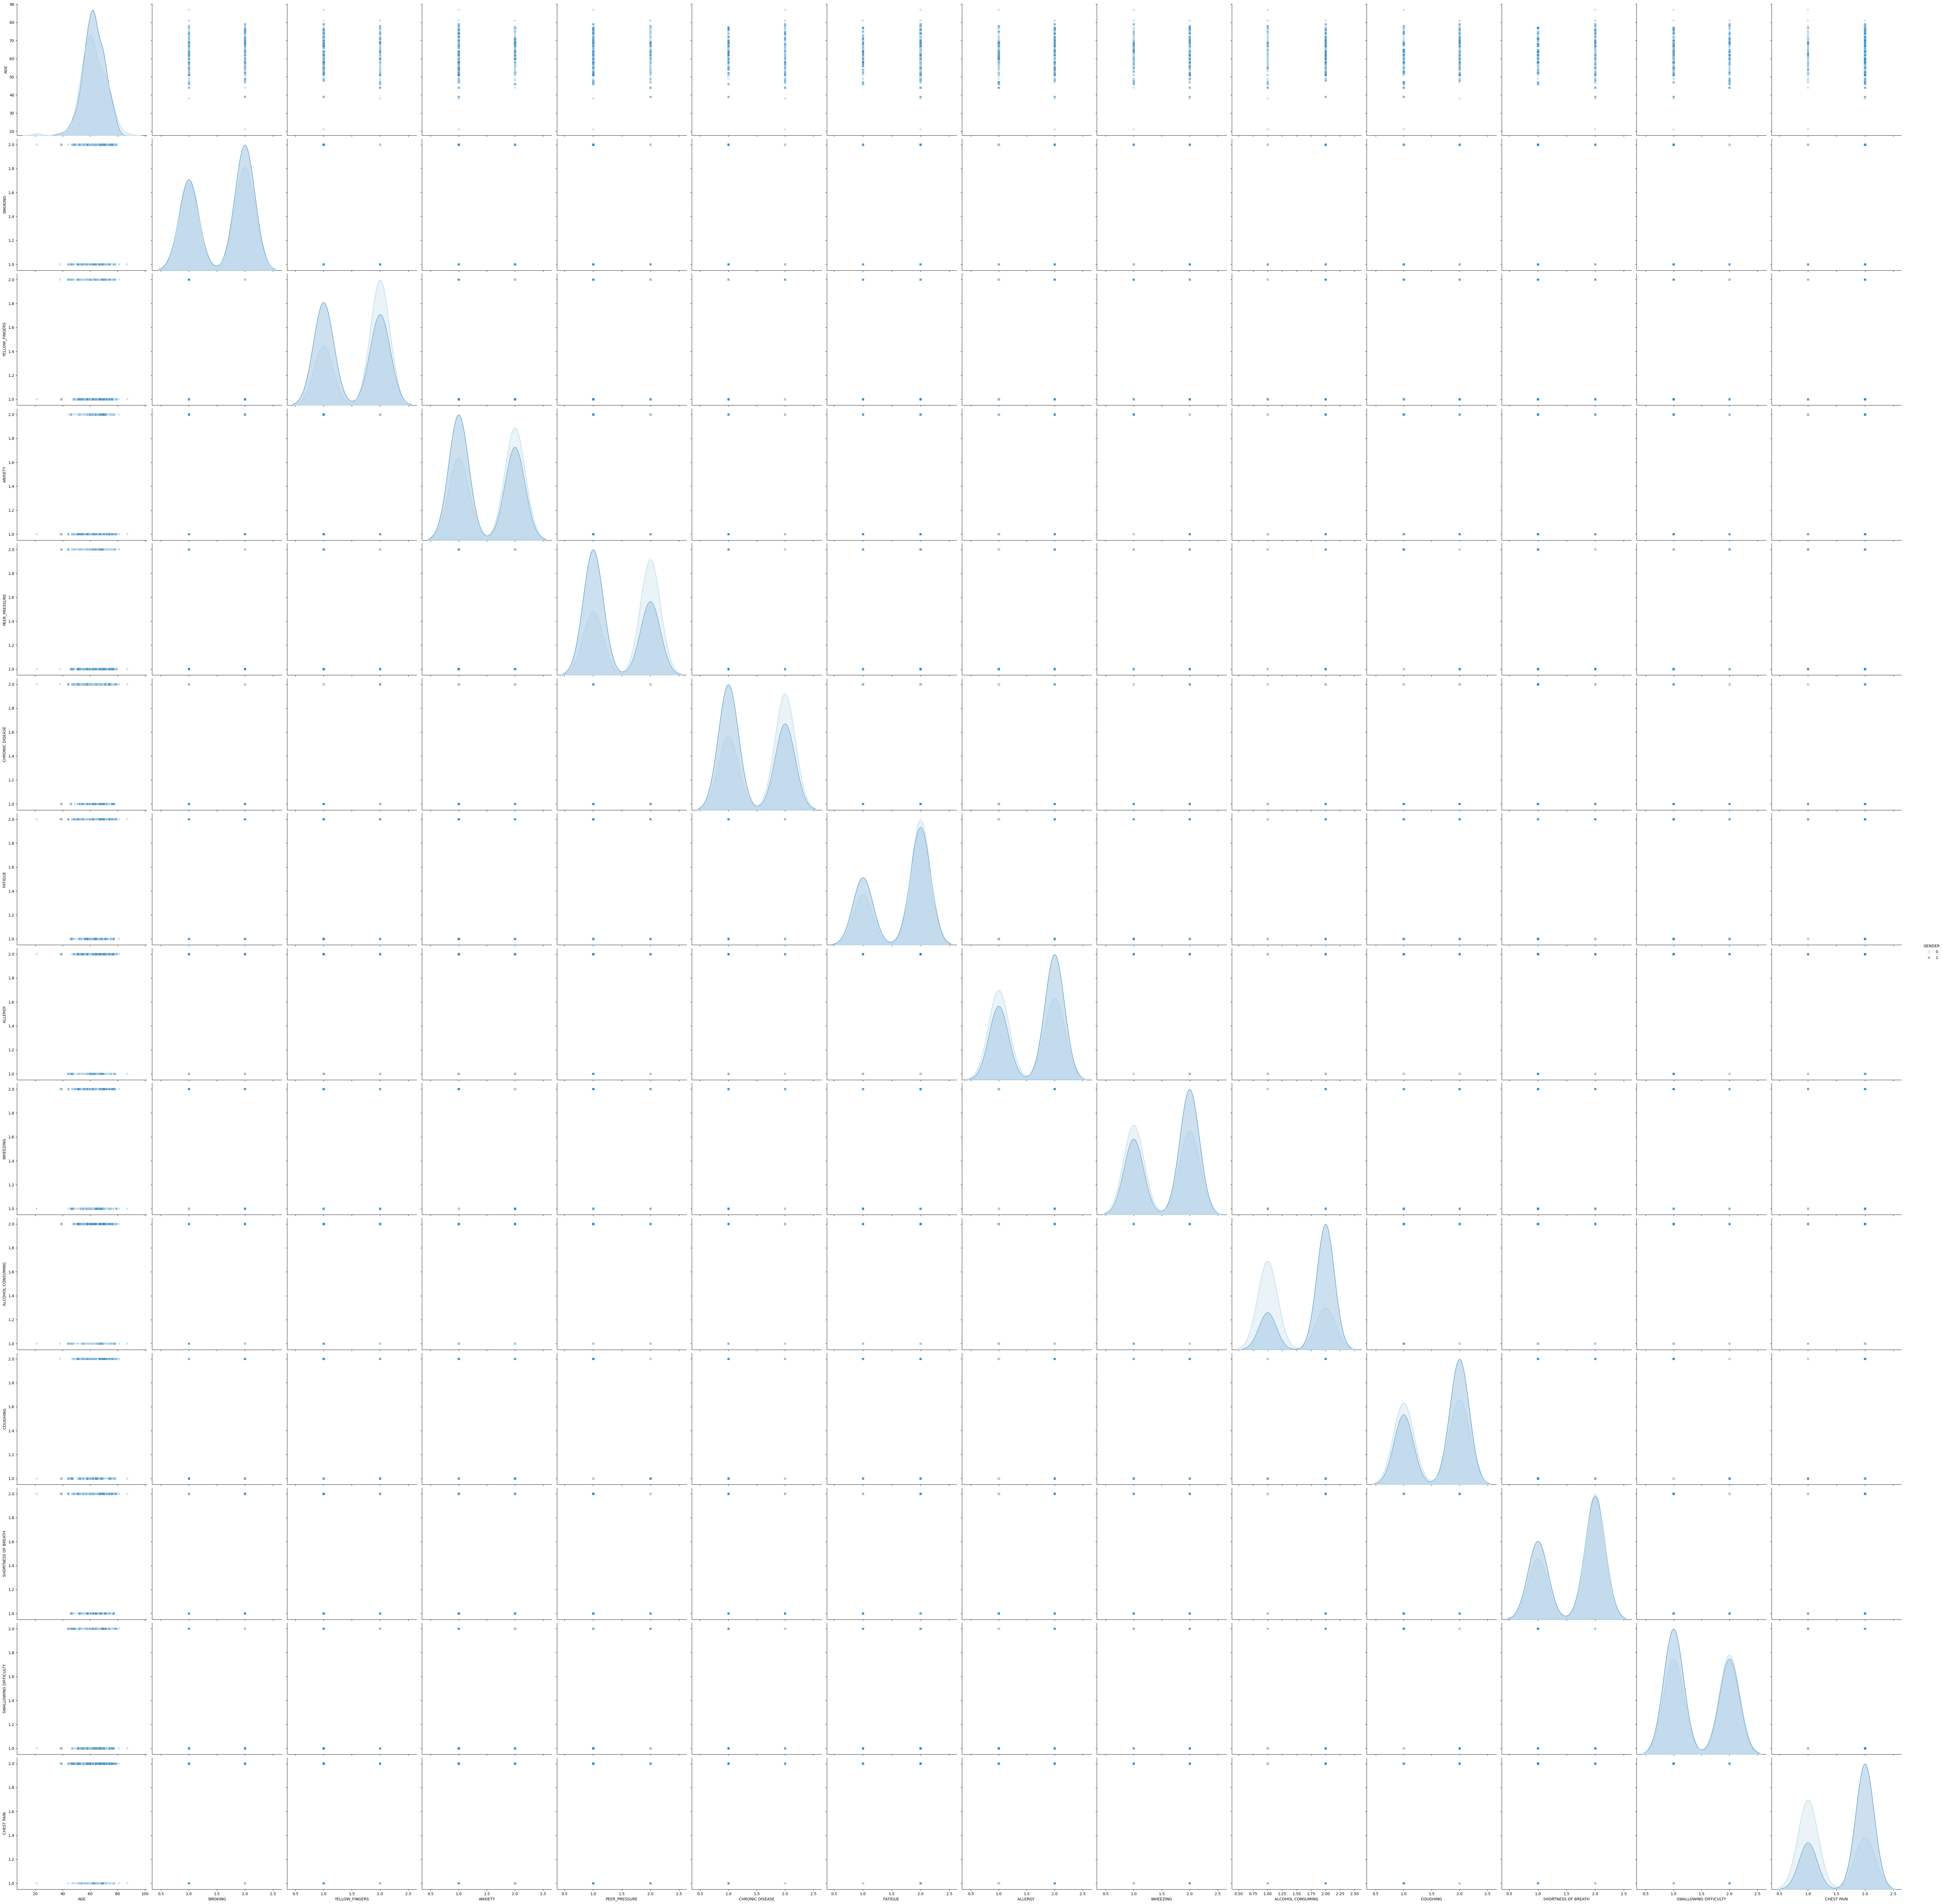

In [ ]:
sns.pairplot(data=x,                 # dataframe
    hue='GENDER',                # color by category
    palette='Blues',          # color theme
    kind='scatter',           # scatter | kde | hist | reg
    diag_kind='kde',          # hist or kde on diagonal
    markers=['o', 's'],       # marker types for categories
    height=5.0,               # size of plots
    corner=False,             # if True: only half the matrix shown
    plot_kws={'alpha':0.6},   # additional args for inner plots
    diag_kws={'shade':True})

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.30,random_state=42)

In [ ]:
print(X_test.shape,X_train.shape,y_test.shape,y_train.shape)

(93, 15) (216, 15) (93,) (216,)


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,roc_auc_score,confusion_matrix

In [ ]:
pred_cls=GradientBoostingClassifier()

In [ ]:
pred_cls.fit(X_train,y_train)

GradientBoostingClassifier()

In [ ]:
training_data_prediction = pred_cls.predict(X_train)

In [ ]:
training_data_prediction

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1])

In [ ]:
y_pred = pred_cls.predict(X_test)
y_prob = pred_cls.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.956989247311828
Recall: 0.9883720930232558
Precision: 0.9659090909090909
F1: 0.9770114942528736
ROC-AUC: 0.9759136212624584
Confusion Matrix:
 [[ 4  3]
 [ 1 85]]


In [ ]:
y_prob

array([0.97497853, 0.99793015, 0.99904825, 0.99987969, 0.99527598,
       0.87210992, 0.99971643, 0.9915632 , 0.97389874, 0.96959893,
       0.90809813, 0.99734115, 0.98620385, 0.90120717, 0.9869536 ,
       0.81167082, 0.9860478 , 0.97090079, 0.99986618, 0.97137063,
       0.56685673, 0.99565766, 0.78358217, 0.99101895, 0.99975726,
       0.48973883, 0.89761945, 0.90655322, 0.99258799, 0.99945235,
       0.99193297, 0.85102987, 0.99787854, 0.9993941 , 0.99810035,
       0.99975726, 0.99876739, 0.98092111, 0.76795834, 0.99484976,
       0.99107777, 0.99933403, 0.9969532 , 0.99594468, 0.9936156 ,
       0.99420546, 0.99986618, 0.99680919, 0.20854399, 0.98374704,
       0.95566654, 0.99307955, 0.99743827, 0.99636994, 0.9969532 ,
       0.97458587, 0.99035036, 0.99289978, 0.70029323, 0.56409625,
       0.9994768 , 0.99937331, 0.72790659, 0.99266395, 0.95541914,
       0.99958503, 0.99965576, 0.99237798, 0.96761797, 0.94159083,
       0.98367013, 0.72790659, 0.99719115, 0.02722049, 0.64763

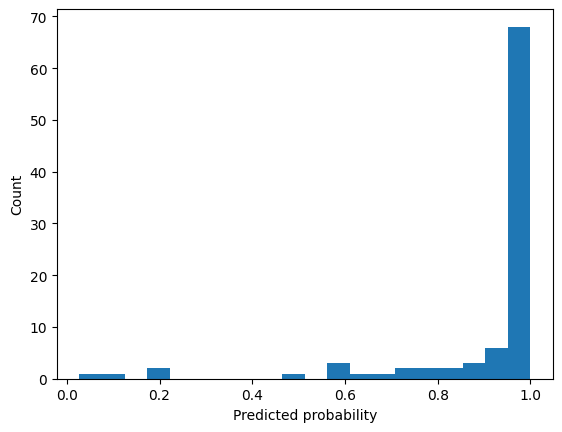

In [ ]:

plt.hist(y_prob, bins=20)
plt.xlabel("Predicted probability")
plt.ylabel("Count")
plt.show()

In [ ]:
pd.Series(y_prob).describe()



,0
count,93.000000
mean,0.907656
std,0.197612
min,0.027220
25%,0.943531
50%,0.991563
75%,0.997183
max,0.999880


In [ ]:
pd.Series(y_prob).value_counts()

,count
0.999866,2
0.991563,2
0.995658,2
0.566857,2
0.993616,2
...,...
0.994423,1
0.941438,1
0.999324,1
0.943531,1
